# 2-loyiha
Bemor oqimi va telemeditsina xizmatini tahlil qilish

patient_flow.csv: takrorlanuvchi sun’iy tashriflar. Kanallar orasidagi farq sababiy ta’sir isboti emas.


In [1]:
# Bemor oqimi va telemeditsina xizmatini tahlil qilish
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = (Path(__file__).resolve().parent
        if "__file__" in globals() else Path.cwd())
DATA, OUT = ROOT / "data", ROOT / "outputs"
DATA.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
SEED = 42

def save_json(name, value):
    text = json.dumps(value, indent=2, ensure_ascii=False,
                      allow_nan=False, default=str)
    (OUT / name).write_text(text, encoding="utf-8")

def save_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=140)
    plt.close()

def main():
    path = DATA / "patient_flow.csv"
    if not path.exists():
        rng = np.random.default_rng(SEED)
        n = 600
        channel = rng.choice(["face_to_face", "telemedicine"], n)
        arrival = pd.Timestamp("2026-01-05 08:00") + pd.to_timedelta(
            rng.integers(0, 5 * 24 * 60, n), unit="m")
        wait = rng.gamma(2, 12, n) + (channel == "face_to_face") * 8
        duration = rng.gamma(3, 5, n)
        start = arrival + pd.to_timedelta(wait, unit="m")
        pd.DataFrame({"visit_id": np.arange(n),
            "department": rng.choice(["A", "B", "C"], n),
            "channel": channel, "arrival_time": arrival,
            "service_start": start,
            "service_end": start + pd.to_timedelta(duration, unit="m")
        }).to_csv(path, index=False)
    df = pd.read_csv(path, parse_dates=["arrival_time",
        "service_start", "service_end"])
    if df.visit_id.duplicated().any():
        raise ValueError("visit_id takrorlangan")
    df["wait_min"] = (df.service_start - df.arrival_time
                      ).dt.total_seconds() / 60
    df["service_min"] = (df.service_end - df.service_start
                         ).dt.total_seconds() / 60
    bad = df[["wait_min", "service_min"]].isna().any(axis=1)
    bad |= (df[["wait_min", "service_min"]] < 0).any(axis=1)
    df.loc[bad].to_csv(OUT / "invalid_rows.csv", index=False)
    clean = df.loc[~bad].copy()
    summary = clean.groupby(["department", "channel"]).agg(
        n=("visit_id", "size"), median_wait=("wait_min", "median"),
        p90_wait=("wait_min", lambda s: s.quantile(0.9)),
        median_service=("service_min", "median"),
        over_30_fraction=("wait_min", lambda s: (s > 30).mean()))
    summary.to_csv(OUT / "department_channel_summary.csv")
    hours = clean.groupby(clean.arrival_time.dt.hour).size()
    hours.to_csv(OUT / "hourly_load.csv", header=["visits"])
    hours.plot.bar(xlabel="Soat", ylabel="Tashriflar soni",
                   title="Bemor oqimi: sun’iy namuna")
    save_plot("hourly_load.png")
    clean.boxplot(column="wait_min", by="channel")
    plt.suptitle("")
    plt.ylabel("Kutish vaqti, daqiqa")
    save_plot("channel_wait.png")
    save_json("summary.json", {"rows": len(df),
        "valid_rows": len(clean), "invalid_rows": int(bad.sum()),
        "busiest_hours": hours.nlargest(3).index.tolist(),
        "data_source": "synthetic"})
    print(summary.to_string())

if __name__ == "__main__":
    main()


                           n  median_wait   p90_wait  median_service  over_30_fraction
department channel                                                                    
A          face_to_face  117    26.455248  56.174503       14.439323          0.410256
           telemedicine  133    20.729970  44.243748       13.250256          0.278195
B          face_to_face   93    25.712347  54.210874       15.421051          0.376344
           telemedicine   77    20.630156  47.632922       14.240722          0.285714
C          face_to_face   94    28.703080  45.827564       13.612797          0.436170
           telemedicine   86    19.773366  45.947561       12.418888          0.255814


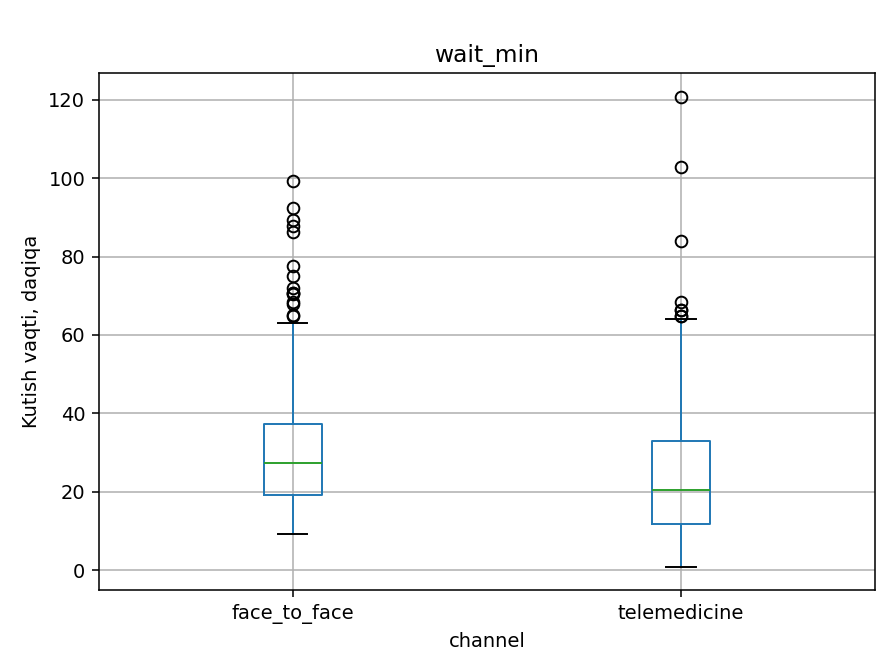

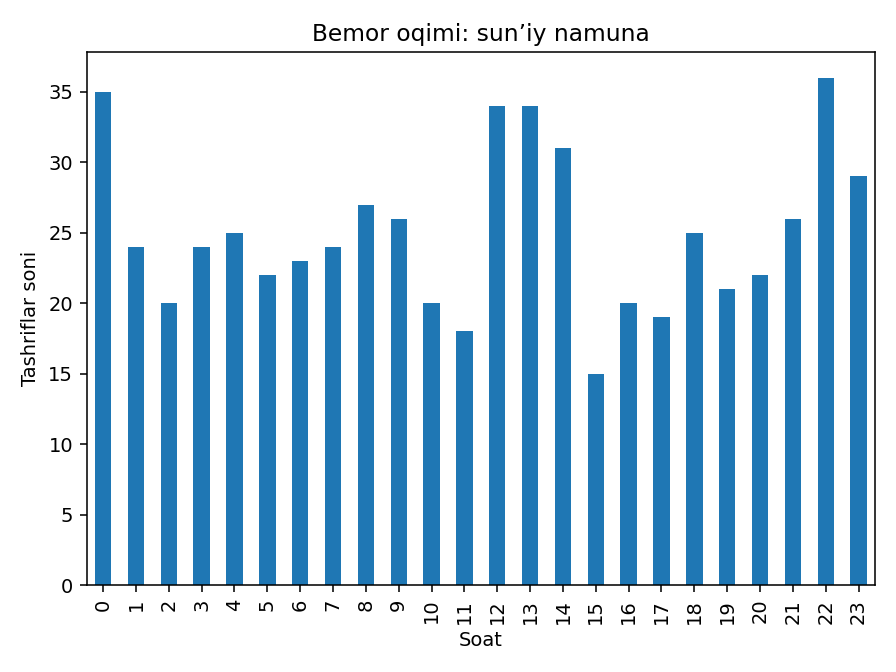

In [2]:
from IPython.display import display, Image
for path in sorted(OUT.glob("*.png")):
    display(Image(filename=str(path)))
